# Exploratory Data Analysis & Statistical Insights
### Internship submission | Retail Superstore order-line data

**Objective.** Audit a real-world teaching dataset, describe sales and profitability, visualize product/customer/geographic/time patterns, and evaluate three business hypotheses using prespecified α = 0.05. Results are associations, not causal effects.

## Dataset and provenance
Sample Superstore order-line CSV (publicly accessible mirror): [source CSV](https://raw.githubusercontent.com/leonism/sample-superstore/master/data/superstore.csv). The mirror describes this as the classic Tableau Sample Superstore dataset. The upstream dataset's redistribution license is not clearly stated; therefore the repository does not redistribute the dataset; the notebook downloads it to `data/cleaned_dataset.csv` when needed. Verify rights before reuse. Data covers US retail transactions and includes order/shipping dates, customer segment, product/category, region, sales, discount, and profit. This is fictional/sample business data, not a live retailer.

### Key columns
`Order ID` (order identifier; rows are line items), `Order Date`, `Segment`, `Region`, `Category`/`Sub-Category`, `Product Name`, `Sales` (USD), `Quantity`, `Discount` (fraction), `Profit` (USD). Customer name/ID and geographic fields are present.

## Methodology
Pandas ingestion and quality checks; preserve valid negative profit as loss; parse dates and numeric fields; remove only exact duplicate rows if encountered. Descriptive summaries, Matplotlib/Seaborn graphics saved under `visualizations/`, robust rank correlation and Welch/Kruskal–Wallis group comparisons, plus effect sizes. Analyses use line-item observations; related lines within orders/customers mean independence assumptions are imperfect. No causal inference.


In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Image
from urllib.request import urlretrieve
ROOT = Path.cwd()
if not (ROOT / "data").exists(): ROOT = ROOT.parent
DATA = ROOT / "data/cleaned_dataset.csv"
if not DATA.exists():
    DATA.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve("https://raw.githubusercontent.com/leonism/sample-superstore/master/data/superstore.csv", DATA)
OUT = ROOT / "visualizations"; OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
df = pd.read_csv(DATA, encoding="utf-8-sig")
print("Raw dimensions:", df.shape)
print("Missing cells:", int(df.isna().sum().sum()), "| exact duplicate rows:", int(df.duplicated().sum()))
df.info()

Raw dimensions: (10800, 21)
Missing cells: 15325 | exact duplicate rows: 504
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   99

## Preparation and data quality
Convert date and numeric columns, inspect domain constraints, and retain observations with valid core metrics. Negative profit is meaningful (loss) and is not removed. Duplicate row removal, if needed, is exact-match only.

In [2]:
before=len(df)
df = df.drop_duplicates().copy()
for c in ["Order Date","Ship Date"]: df[c]=pd.to_datetime(df[c], errors="coerce")
for c in ["Sales","Profit","Discount","Quantity"]: df[c]=pd.to_numeric(df[c], errors="coerce")
core=["Order Date","Sales","Profit","Discount","Segment","Category","Region"]
missing_core=int(df[core].isna().any(axis=1).sum())
df=df.dropna(subset=core).copy()
invalid={"nonpositive_sales":int((df.Sales<=0).sum()),"negative_quantity":int((df.Quantity<0).sum()),"discount_outside_0_1":int((~df.Discount.between(0,1)).sum()),"ship_before_order":int((df["Ship Date"]<df["Order Date"]).sum())}
print(f"Exact duplicates removed: {before-len(df)}; rows removed for missing core values: {missing_core}")
print("Domain audit:",invalid)
print("Analysis rows:",len(df),"date range:",df["Order Date"].min().date(),"to",df["Order Date"].max().date())
df["Profit Margin"]=df.Profit/df.Sales
df["Order Month"]=df["Order Date"].dt.to_period("M").dt.to_timestamp()
df.to_csv(DATA,index=False)
df.head()

Exact duplicates removed: 806; rows removed for missing core values: 302
Domain audit: {'nonpositive_sales': 0, 'negative_quantity': 0, 'discount_outside_0_1': 0, 'ship_before_order': 0}
Analysis rows: 9994 date range: 2015-01-03 to 2018-12-30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin,Order Month
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,0.1600,2017-11-01
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,0.3000,2017-11-01
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,0.4700,2017-06-01
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,-0.4000,2016-10-01
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,0.1125,2016-10-01


## Descriptive statistics
The numerical table includes mean, median, sample standard deviation and variance, extrema, quartiles and IQR. Category summaries count distinct values and report the most frequent category.

In [3]:
nums=["Sales","Profit","Discount","Quantity","Profit Margin"]
desc=df[nums].describe(percentiles=[.25,.5,.75]).T
desc["variance"]=df[nums].var()
desc["IQR"]=desc["75%"]-desc["25%"]
display(desc[["mean","50%","std","variance","min","25%","75%","max","IQR"]].round(4))
display(df[["Segment","Category","Region","Sub-Category","Ship Mode"]].describe().T)

,mean,50%,std,variance,min,25%,75%,max,IQR
Sales,229.8580,54.4900,623.2451,388434.4553,0.444,17.2800,209.9400,22638.480,192.6600
Profit,28.6569,8.6665,234.2601,54877.7981,-6599.978,1.7288,29.3640,8399.976,27.6352
Discount,0.1562,0.2000,0.2065,0.0426,0.000,0.0000,0.2000,0.800,0.2000
Quantity,3.7896,3.0000,2.2251,4.9511,1.000,2.0000,5.0000,14.000,3.0000
Profit Margin,0.1203,0.2700,0.4668,0.2179,-2.750,0.0750,0.3625,0.500,0.2875


,count,unique,top,freq
Segment,9994,3,Consumer,5191
Category,9994,3,Office Supplies,6026
Region,9994,4,West,3203
Sub-Category,9994,17,Binders,1523
Ship Mode,9994,4,Standard Class,5968


## Visual exploratory analysis
All charts are saved as portable PNGs and shown inline below. Boxplot whiskers indicate 1.5×IQR; flagged points are potential outliers, not necessarily errors.

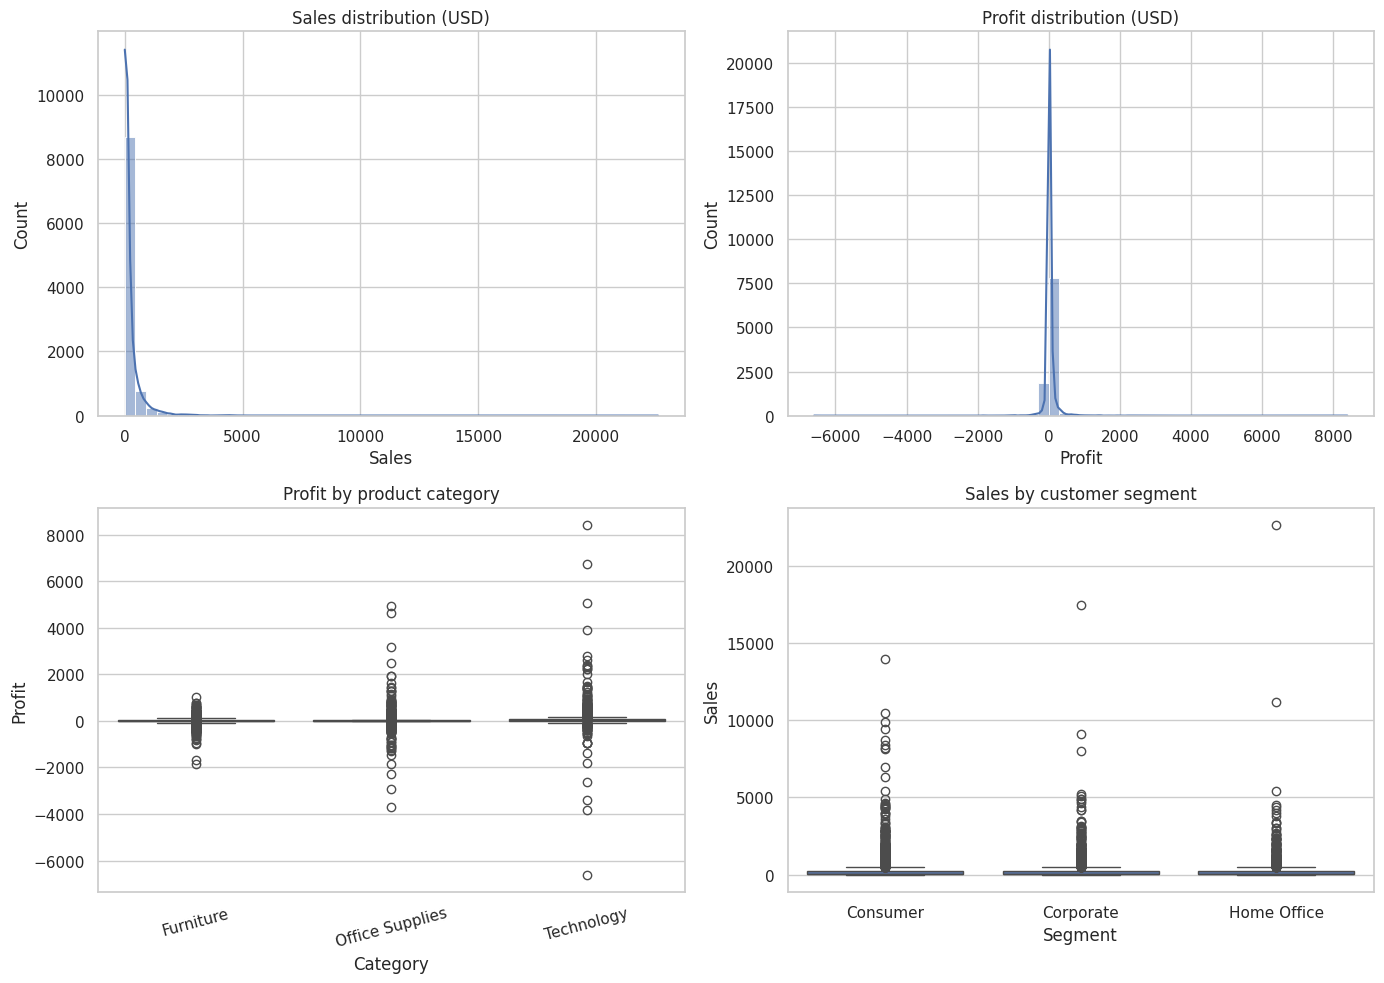

In [4]:
fig,ax=plt.subplots(2,2,figsize=(14,10))
sns.histplot(df.Sales,bins=50,kde=True,ax=ax[0,0]); ax[0,0].set_title("Sales distribution (USD)")
sns.histplot(df.Profit,bins=50,kde=True,ax=ax[0,1]); ax[0,1].set_title("Profit distribution (USD)")
sns.boxplot(data=df,x="Category",y="Profit",ax=ax[1,0]); ax[1,0].tick_params(axis="x",rotation=15); ax[1,0].set_title("Profit by product category")
sns.boxplot(data=df,x="Segment",y="Sales",ax=ax[1,1]); ax[1,1].set_title("Sales by customer segment")
fig.tight_layout(); fig.savefig(OUT/"distributions_boxplots.png",dpi=160); plt.show()

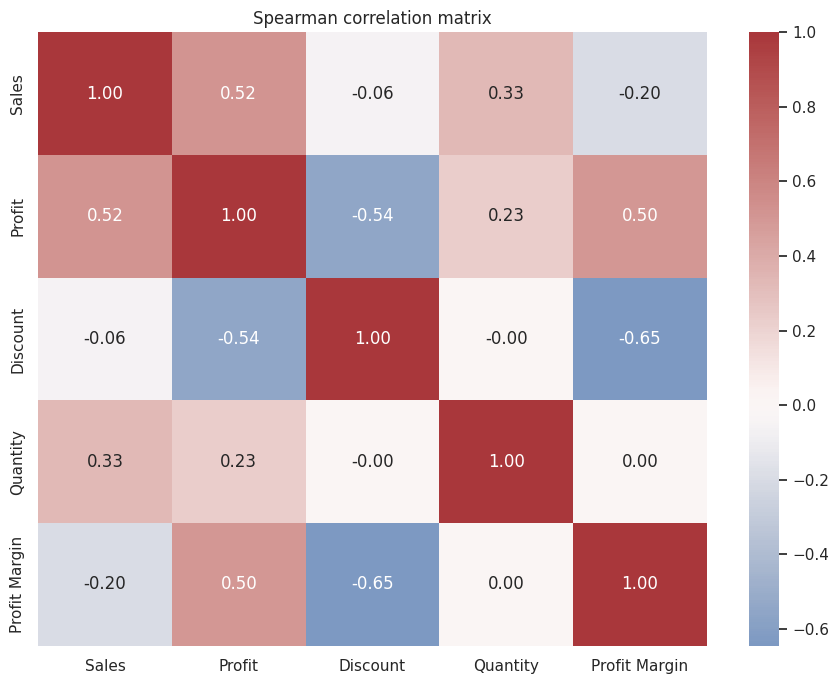

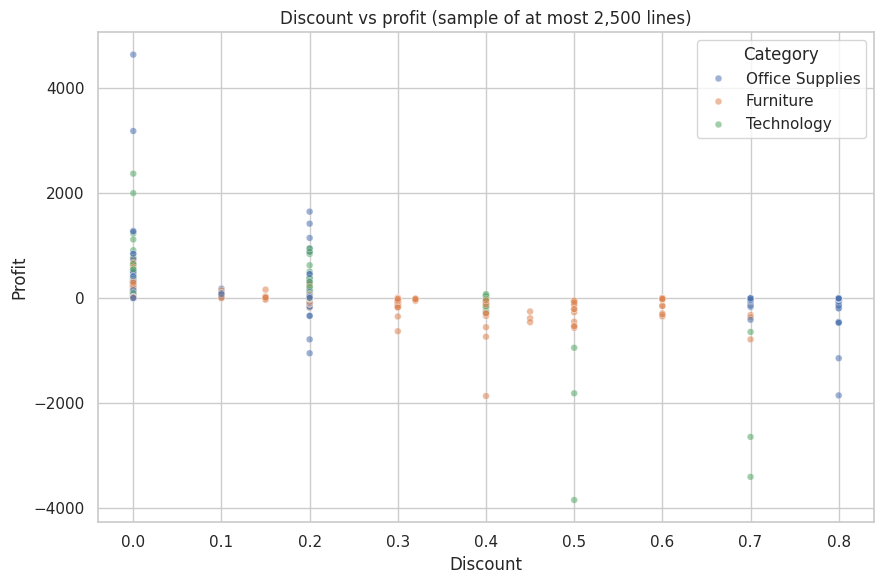

In [5]:
fig,ax=plt.subplots(figsize=(9,7)); corr=df[nums].corr(method="spearman"); sns.heatmap(corr,annot=True,cmap="vlag",center=0,fmt=".2f",ax=ax); ax.set_title("Spearman correlation matrix"); fig.tight_layout(); fig.savefig(OUT/"correlation_heatmap.png",dpi=160); plt.show()
fig,ax=plt.subplots(figsize=(9,6)); sample=df.sample(min(2500,len(df)),random_state=42); sns.scatterplot(data=sample,x="Discount",y="Profit",hue="Category",alpha=.55,s=24,ax=ax); ax.set_title("Discount vs profit (sample of at most 2,500 lines)"); fig.tight_layout(); fig.savefig(OUT/"discount_profit_scatter.png",dpi=160); plt.show()

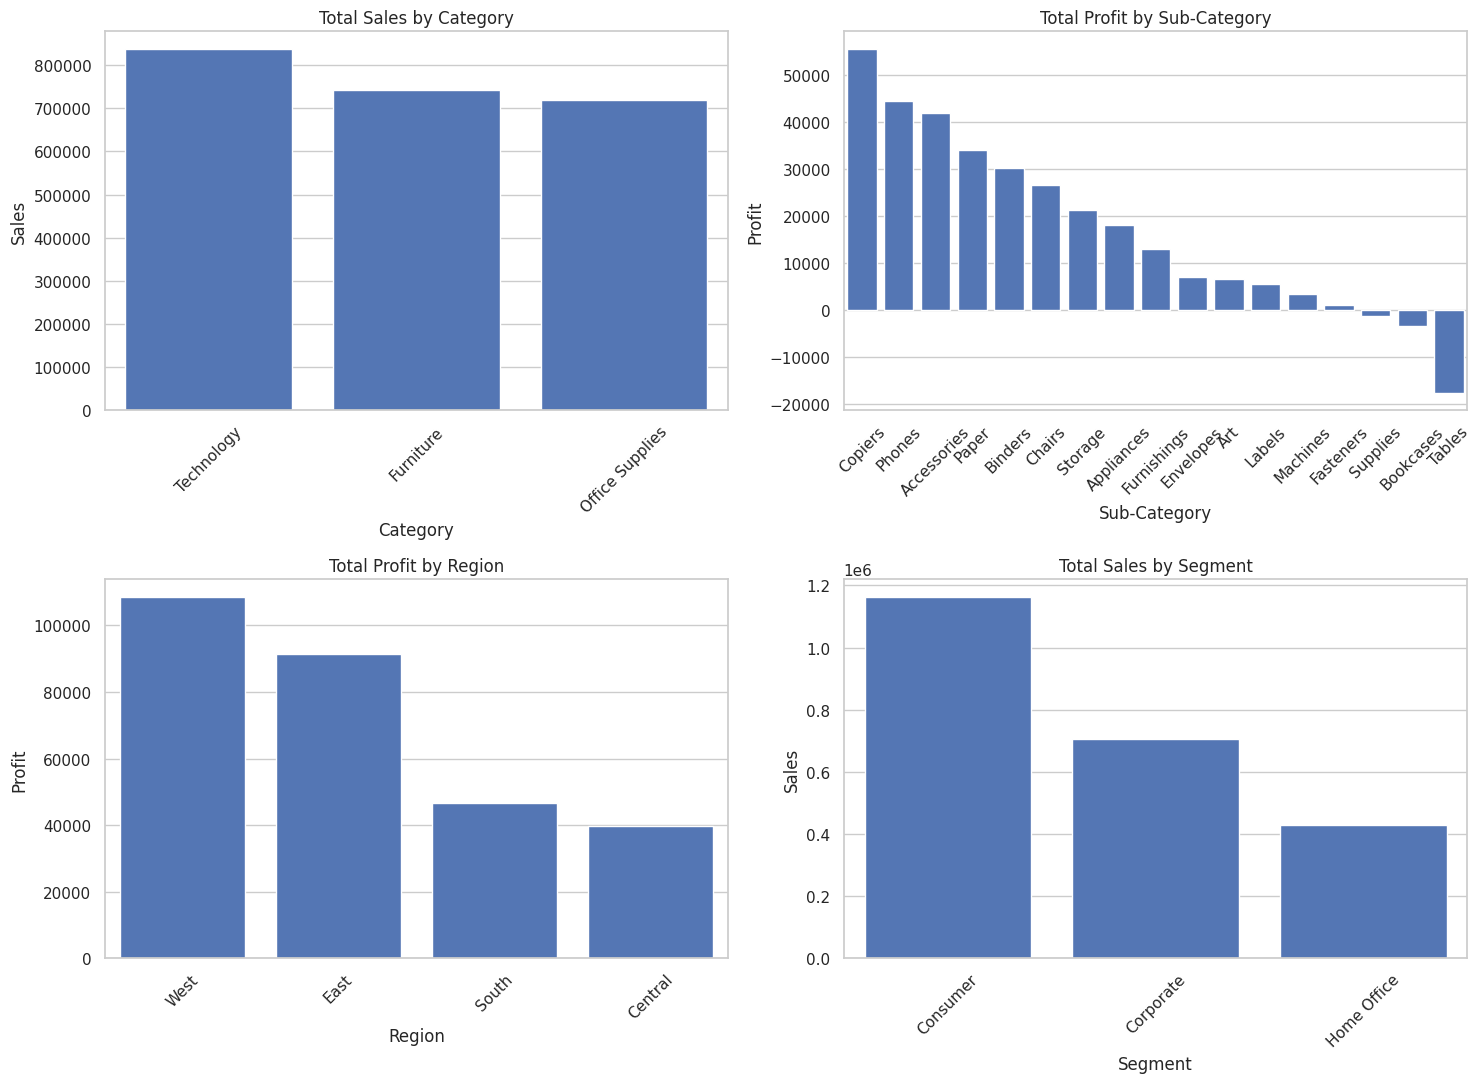

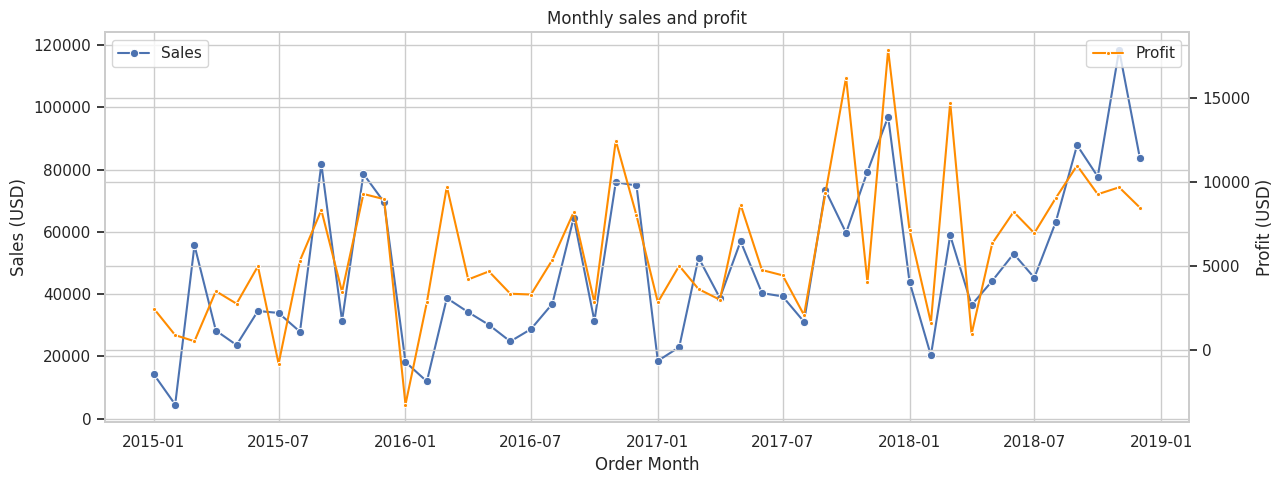

In [6]:
fig,axs=plt.subplots(2,2,figsize=(15,11))
for col,ax,metric in [("Category",axs[0,0],"Sales"),("Sub-Category",axs[0,1],"Profit"),("Region",axs[1,0],"Profit"),("Segment",axs[1,1],"Sales")]:
    order=df.groupby(col)[metric].sum().sort_values(ascending=False).index
    sns.barplot(data=df,x=col,y=metric,estimator=sum,errorbar=None,order=order,ax=ax,color="#4472C4"); ax.set_title(f"Total {metric} by {col}"); ax.tick_params(axis="x",rotation=45)
fig.tight_layout(); fig.savefig(OUT/"business_comparisons.png",dpi=160); plt.show()
monthly=df.groupby("Order Month").agg(Sales=("Sales","sum"),Profit=("Profit","sum")).reset_index()
fig,ax=plt.subplots(figsize=(13,5)); sns.lineplot(data=monthly,x="Order Month",y="Sales",marker="o",ax=ax,label="Sales"); ax2=ax.twinx(); sns.lineplot(data=monthly,x="Order Month",y="Profit",marker=".",color="darkorange",ax=ax2,label="Profit"); ax.set_title("Monthly sales and profit"); ax.set_ylabel("Sales (USD)"); ax2.set_ylabel("Profit (USD)"); fig.tight_layout(); fig.savefig(OUT/"monthly_trends.png",dpi=160); plt.show()

## Hypothesis tests
H1 is assessed by Spearman correlation between discount and line-item profit margin (profit/sales), with bootstrap-free large-sample 95% CI for rho via Fisher transform only as an approximation. H2 and H3 test profit differences among categories/segments and regions using Kruskal–Wallis (robust to skew/outliers); report eta-squared-style H effect. H0: all group distributions are alike; H1: at least one differs. For group tests, uncertainty is reflected in p-values and effect size; exploratory testing is not multiplicity-adjusted. Significance alone does not imply business importance.

In [7]:
alpha=.05
# H1 rank correlation on profit margin; report rho, p and approximate Fisher-z interval
rho,p1=stats.spearmanr(df.Discount,df["Profit Margin"])
n=len(df); z=np.arctanh(np.clip(rho,-.999999,.999999)); se=1/np.sqrt(n-3); ci1=np.tanh([z-1.96*se,z+1.96*se])
print(f"H1 H0: rho=0; H1: rho<0 (two-sided test reported). Spearman rho={rho:.4f}, p={p1:.3g}, approximate 95% CI [{ci1[0]:.4f}, {ci1[1]:.4f}]. Decision: {'reject' if p1<alpha else 'do not reject'} H0 at alpha={alpha}.")
def kw_test(group_col, value_col):
    groups=[g[value_col].dropna().values for _,g in df.groupby(group_col)]
    H,p=stats.kruskal(*groups); k=len(groups); effect=max(0,(H-k+1)/(len(df)-k))
    print(f"{group_col}: Kruskal-Wallis H={H:.3f}, df={k-1}, p={p:.3g}, epsilon-squared={effect:.4f}; {'reject' if p<alpha else 'do not reject'} equal-distribution H0.")
    return H,p,effect
h2cat=kw_test("Category","Profit"); h2seg=kw_test("Segment","Profit"); h3=kw_test("Region","Profit")
print("Note: groups are imbalanced and observations may cluster within orders/customers; inference is exploratory.")

H1 H0: rho=0; H1: rho<0 (two-sided test reported). Spearman rho=-0.6451, p=0, approximate 95% CI [-0.6564, -0.6335]. Decision: reject H0 at alpha=0.05.
Category: Kruskal-Wallis H=445.897, df=2, p=1.5e-97, epsilon-squared=0.0444; reject equal-distribution H0.
Segment: Kruskal-Wallis H=4.373, df=2, p=0.112, epsilon-squared=0.0002; do not reject equal-distribution H0.
Region: Kruskal-Wallis H=227.900, df=3, p=3.93e-49, epsilon-squared=0.0225; reject equal-distribution H0.
Note: groups are imbalanced and observations may cluster within orders/customers; inference is exploratory.


## Five evidence-based business findings and recommendations
Computed below directly from the audited dataset. Interpret results as descriptive association; investigate operational causes before intervention.

In [8]:
cat=df.groupby("Category").agg(Sales=("Sales","sum"),Profit=("Profit","sum"),Margin=("Profit","sum"))
cat["Margin"]=cat.Profit/cat.Sales
seg=df.groupby("Segment").agg(Sales=("Sales","sum"),Profit=("Profit","sum"),n=("Profit","size"))
reg=df.groupby("Region").agg(Sales=("Sales","sum"),Profit=("Profit","sum"),n=("Profit","size"))
sub=df.groupby("Sub-Category").agg(Sales=("Sales","sum"),Profit=("Profit","sum")); worst=sub.sort_values("Profit").iloc[0]; best=sub.sort_values("Profit").iloc[-1]
loss=df[df.Profit<0]; discount_rho=rho
findings=[
 f"1. **Profitability by category.** Highest aggregate margin: {cat.Margin.idxmax()} ({cat.Margin.max():.1%}); lowest: {cat.Margin.idxmin()} ({cat.Margin.min():.1%}). Across the categories, total sales were ${df.Sales.sum():,.0f} and profit ${df.Profit.sum():,.0f}. Recommendation: prioritize margin alongside revenue in category plans, and validate category-level cost/discount drivers. Limitation: aggregate margin can hide SKU mix.",
 f"2. **Discount and return.** Discount vs line-item profit-margin Spearman rho={rho:.3f} (p={p1:.3g}, approximate 95% CI {ci1[0]:.3f} to {ci1[1]:.3f}). Recommendation: review markdown guardrails and contribution margin by SKU before broad discounting. Limitation: observational correlation; pricing, product mix, and order context confound.",
 f"3. **Sub-category extremes.** Lowest-profit sub-category: {worst.name} (${worst.Profit:,.0f}); highest: {best.name} (${best.Profit:,.0f}). Recommendation: conduct SKU-level cost, return, and promotion review for the loss leader; protect availability for strong contributors. Limitation: no unit cost or return data.",
 f"4. **Regional mix.** Highest total profit region: {reg.Profit.idxmax()} (${reg.Profit.max():,.0f}); lowest: {reg.Profit.idxmin()} (${reg.Profit.min():,.0f}). Kruskal-Wallis region test p={h3[1]:.3g}, effect ε²={h3[2]:.3f}. Recommendation: compare regional assortment, discounting and fulfillment; avoid assuming regional differences are causal.",
 f"5. **Loss-making lines.** {len(loss):,} of {len(df):,} lines ({len(loss)/len(df):.1%}) have negative profit; their combined profit is ${loss.Profit.sum():,.0f}. Recommendation: build exception monitoring around repeated loss-making combinations of product, discount, and region. Limitation: line-level profitability omits overhead and returns."
]
for x in findings: print(x,"\n")
summary='\n\n'.join('- '+x for x in findings)
(ROOT/"reports/EDA_Findings_Summary.md").write_text('# EDA Findings Summary\n\n'+summary+'\n\n**Caution:** sample fictional retail transactions; observational, line-level analysis; no causal conclusions. Statistical tests are exploratory and not multiplicity-adjusted.\n')

1. **Profitability by category.** Highest aggregate margin: Technology (17.4%); lowest: Furniture (2.5%). Across the categories, total sales were $2,297,201 and profit $286,397. Recommendation: prioritize margin alongside revenue in category plans, and validate category-level cost/discount drivers. Limitation: aggregate margin can hide SKU mix. 

2. **Discount and return.** Discount vs line-item profit-margin Spearman rho=-0.645 (p=0, approximate 95% CI -0.656 to -0.634). Recommendation: review markdown guardrails and contribution margin by SKU before broad discounting. Limitation: observational correlation; pricing, product mix, and order context confound. 

3. **Sub-category extremes.** Lowest-profit sub-category: Tables ($-17,725); highest: Copiers ($55,618). Recommendation: conduct SKU-level cost, return, and promotion review for the loss leader; protect availability for strong contributors. Limitation: no unit cost or return data. 

4. **Regional mix.** Highest total profit region

1728

## Limitations and conclusion
This is a synthetic/educational Sample Superstore dataset and cannot establish generalizable market facts. Order-line data can violate independence because lines share orders, customers, and products. Profit may be skewed and sensitive to outliers; tests are exploratory and p-values are not corrected across multiple comparisons. There is no cost decomposition, return status, marketing exposure, or stock availability. The findings support targeted follow-up analysis, not causal claims. The complete generated report is in `reports/EDA_Findings_Summary.md`.